In [ ]:
import os
import xml.etree.ElementTree as ET



In [2]:
ANNOTATIONS_DIR = './Tomato/annotations'
LABELS_DIR = './Tomato/labels'
os.makedirs(LABELS_DIR, exist_ok=True)

classes = ['tomato']

In [3]:

def convert(size, box):
    dw = 1. / size[0]
    dh = 1. / size[1]
    x_center = (box[0] + box[1]) / 2.0
    y_center = (box[2] + box[3]) / 2.0
    w = box[1] - box[0]
    h = box[3] - box[2]
    return x_center * dw, y_center * dh, w * dw, h * dh
for filename in os.listdir(ANNOTATIONS_DIR):
    if not filename.endswith('.xml'):
        continue

    xml_path = os.path.join(ANNOTATIONS_DIR, filename)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find('size')
    w = int(size.find('width').text)
    h = int(size.find('height').text)

    out_file = open(os.path.join(LABELS_DIR, filename.replace('.xml', '.txt')), 'w')

    for obj in root.iter('object'):
        cls = obj.find('name').text
        if cls not in classes:
            continue
        cls_id = classes.index(cls)
        xmlbox = obj.find('bndbox')
        b = (int(xmlbox.find('xmin').text),
             int(xmlbox.find('xmax').text),
             int(xmlbox.find('ymin').text),
             int(xmlbox.find('ymax').text))
        bb = convert((w, h), b)
        out_file.write(f"{cls_id} {' '.join([str(round(a, 6)) for a in bb])}\n")

In [ ]:
import shutil
!pip install scikit-learn

from sklearn.model_selection import train_test_split

  Using cached joblib-1.5.1-py3-none-any.whl.metadata (5.6 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 2.7 MB/s eta 0:00:00a 0:00:01
Using cached joblib-1.5.1-py3-none-any.whl (307 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [scikit-learn] [scikit-learn]


In [6]:

images_dir = './Tomato/images'
labels_dir = './Tomato/labels'

train_images_dir = './Tomato/images/train'
val_images_dir = './Tomato/images/val'
train_labels_dir = './Tomato/labels/train'
val_labels_dir = './Tomato/labels/val'

for d in [train_images_dir, val_images_dir, train_labels_dir, val_labels_dir]:
    os.makedirs(d, exist_ok=True)

images = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))]
train_imgs, val_imgs = train_test_split(images, test_size=0.2, random_state=42)

for img in train_imgs:
    shutil.move(os.path.join(images_dir, img), os.path.join(train_images_dir, img))
    shutil.move(os.path.join(labels_dir, img.replace('.png', '.txt').replace('.jpg', '.txt')), os.path.join(train_labels_dir, img.replace('.png', '.txt').replace('.jpg', '.txt')))

for img in val_imgs:
    shutil.move(os.path.join(images_dir, img), os.path.join(val_images_dir, img))
    shutil.move(os.path.join(labels_dir, img.replace('.png', '.txt').replace('.jpg', '.txt')), os.path.join(val_labels_dir, img.replace('.png', '.txt').replace('.jpg', '.txt')))


In [7]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

100%|██████████| 6.25M/6.25M [00:03<00:00, 1.96MB/s]


In [10]:
trained = model.train(
    data= './Tomato/data.yaml',
    epochs=20,
    imgsz=640,)

New https://pypi.org/project/ultralytics/8.3.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./Tomato/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_ma

train: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/labels/train... 716 images, 1 backgrounds, 0 corrupt: 100%|██████████| 716/716 [00:00<00:00, 2517.51it/s]

train: New cache created: /Users/rokiialaa/Downloads/Tomato/Tomato/labels/train.cache
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 538.5±117.1 MB/s, size: 204.6 KB)



val: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/labels/val... 179 images, 0 backgrounds, 0 corrupt: 100%|██████████| 179/179 [00:00<00:00, 3031.03it/s]

val: New cache created: /Users/rokiialaa/Downloads/Tomato/Tomato/labels/val.cache


...

                   all        179       1026      0.705      0.692      0.734      0.419

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size



       6/20         0G        1.5      1.083      1.271        101        640: 100%|██████████| 45/45 [04:12<00:00,  5.61s/it]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 6/6 [00:24<00:00,  4.17s/it]

                   all        179       1026      0.791       0.67      0.754       0.43

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size



       7/20         0G      1.498      1.145       1.28        177        640:  20%|██        | 9/45 [00:55<03:41,  6.15s/it]


KeyboardInterrupt: 

In [11]:
model = YOLO('runs/detect/train3/weights/last.pt')
model.train(resume=True)


New https://pypi.org/project/ultralytics/8.3.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./Tomato/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=runs/detect/train3/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train3, nbs=64, nms=False, opset=None, optimize=False, op

train: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/labels/train.cache... 716 images, 1 backgrounds, 0 corrupt: 100%|██████████| 716/716 [00:00<?, ?it/s]

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 362.9±173.8 MB/s, size: 204.6 KB)



val: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/labels/val.cache... 179 images, 0 backgrounds, 0 corrupt: 100%|██████████| 179/179 [00:00<?, ?it/s]


Plotting labels to runs/detect/train3/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.002, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Resuming training runs/detect/train3/weights/last.pt from epoch 7 to 20 total epochs
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to runs/detect/train3
Starting training for 20 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...

                   all        179       1026      0.868      0.821      0.906      0.563

14 epochs completed in 1.056 hours.


Optimizer stripped from runs/detect/train3/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train3/weights/best.pt, 6.2MB

Validating runs/detect/train3/weights/best.pt...
Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 6/6 [00:22<00:00,  3.77s/it]


                   all        179       1026      0.869      0.821      0.906      0.563
Speed: 0.9ms preprocess, 116.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to runs/detect/train3


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x300756350>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048,    

In [16]:
import random

def create_sample_dataset():
    images_dir = './Tomato/images/val'
    labels_dir = './Tomato/labels/val'

    sample_images_dir = './Tomato/sample/images'
    sample_labels_dir = './Tomato/sample/labels'

    os.makedirs(sample_images_dir, exist_ok=True)
    os.makedirs(sample_labels_dir, exist_ok=True)

    all_images = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))]
    sample_size = min(10, len(all_images))    
    sample_images = random.sample(all_images, sample_size)
    
    for img in sample_images:
        shutil.copy(os.path.join(images_dir, img), os.path.join(sample_images_dir, img))
        label_file = img.replace('.png', '.txt').replace('.jpg', '.txt')
        if os.path.exists(os.path.join(labels_dir, label_file)):
            shutil.copy(os.path.join(labels_dir, label_file), os.path.join(sample_labels_dir, label_file))
    print(f"Found {len(all_images)} images, sampling {sample_size}")

create_sample_dataset()



Found 179 images, sampling 10


In [17]:
model = YOLO('runs/detect/train3/weights/best.pt')

In [18]:
sample_pred = model.predict(source = './Tomato/sample/images', save=True, save_txt=True, name = 'sample_predictions')


image 1/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato141.png: 640x512 16 tomatos, 81.8ms
image 2/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato200.png: 640x512 6 tomatos, 57.7ms
image 3/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato272.png: 640x512 17 tomatos, 69.6ms
image 4/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato370.png: 640x512 2 tomatos, 55.0ms
image 5/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato395.png: 640x512 4 tomatos, 51.0ms
image 6/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato461.png: 640x512 4 tomatos, 51.2ms
image 7/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato49.png: 640x512 2 tomatos, 53.4ms
image 8/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato52.png: 512x640 1 tomato, 50.6ms
image 9/10 /Users/rokiialaa/Downloads/Tomato/Tomato/sample/images/tomato667.png: 512x640 27 tomatos, 53.5ms
image 10/10 /Users/rokiialaa/Downloa

In [20]:
import os
import cv2
import matplotlib.pyplot as plt


sample_img_dir = './Tomato/sample/images'
gt_sample_label_dir = './Tomato/sample/labels'
pred_sample_label_dir = './Tomato/sample_predictions/labels'

def draw_boxes(img, label_path, color, label_type):
    h, w = img.shape[:2]
    if not os.path.exists(label_path):
        return img
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls, xc, yc, bw, bh = map(float, parts[:5])
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, f'{label_type}: {int(cls)}', (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return img

In [23]:
image_files = [f for f in os.listdir(sample_img_dir) if f.endswith(('.jpg', '.png'))]

for img_file in image_files:
    img_path = os.path.join(sample_img_dir, img_file)
    gt_path = os.path.join(gt_sample_label_dir, os.path.splitext(img_file)[0] + '.txt')
    pred_path = os.path.join(pred_sample_label_dir, os.path.splitext(img_file)[0] + '.txt')

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Draw GT in green, predictions in red
    img_with_gt = draw_boxes(img.copy(), gt_path, (0, 255, 0), 'GT')
    img_with_all = draw_boxes(img_with_gt, pred_path, (255, 0, 0), 'Pred')

    # Show image
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_all)
    plt.title(f"GT vs Prediction: {img_file}")
    plt.axis('off')
    plt.show()

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

<Figure size 1000x1000 with 1 Axes>

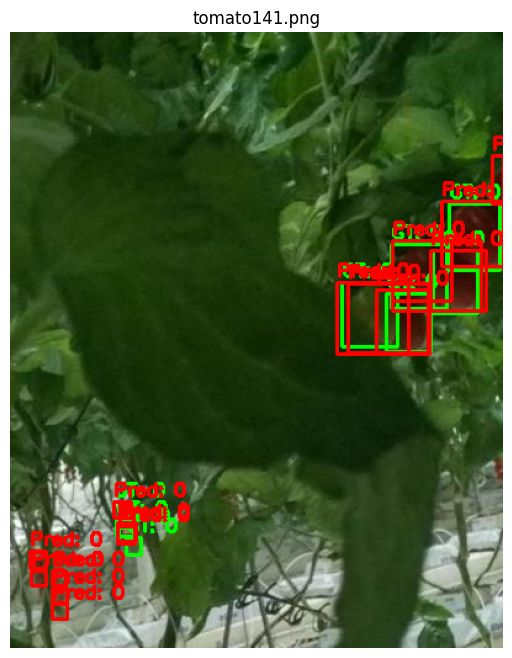

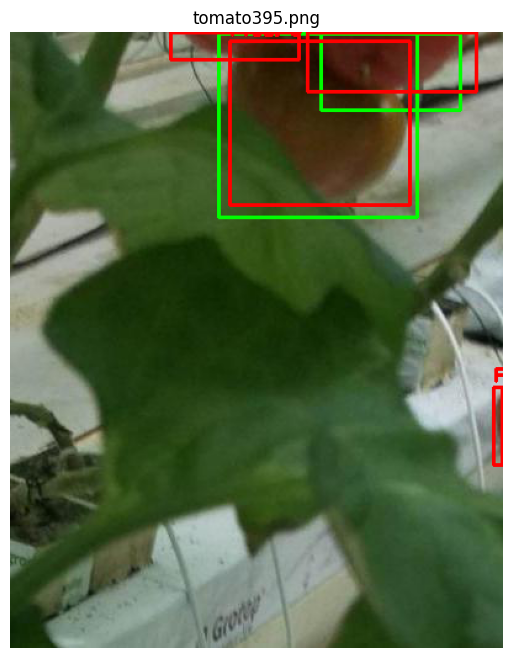

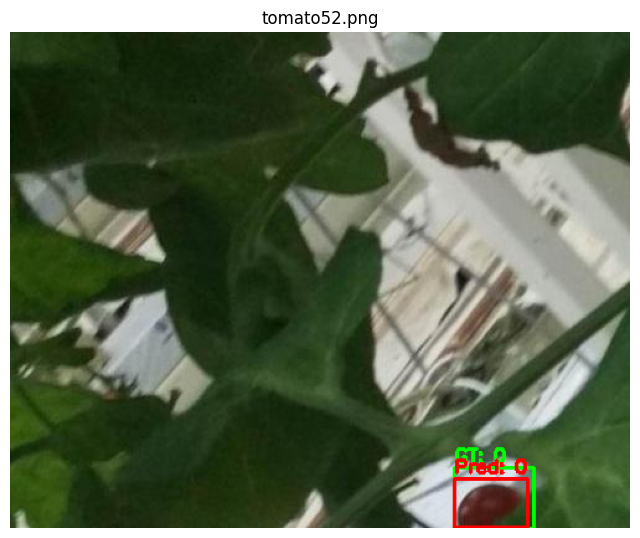

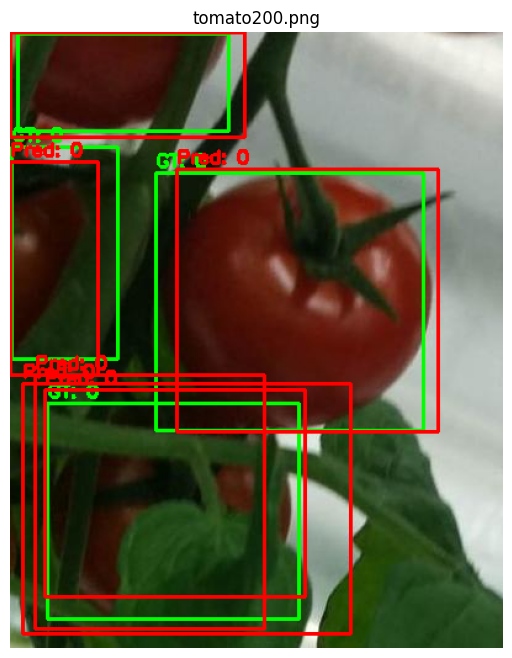

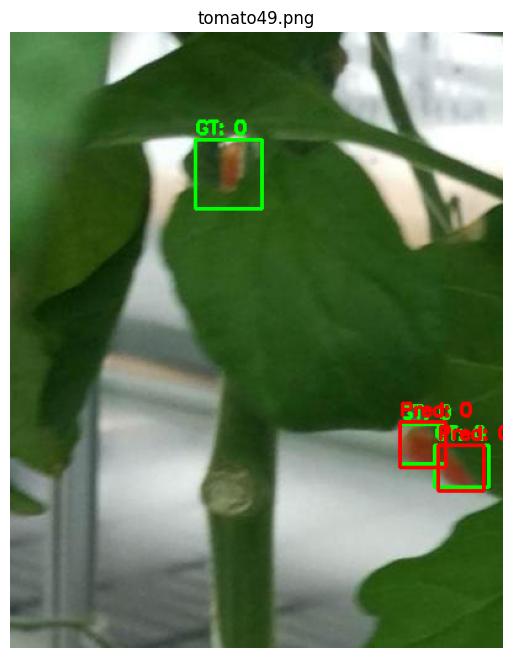

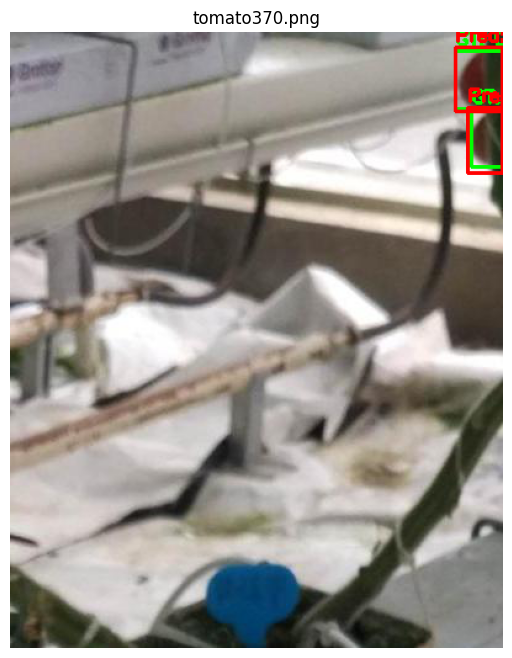

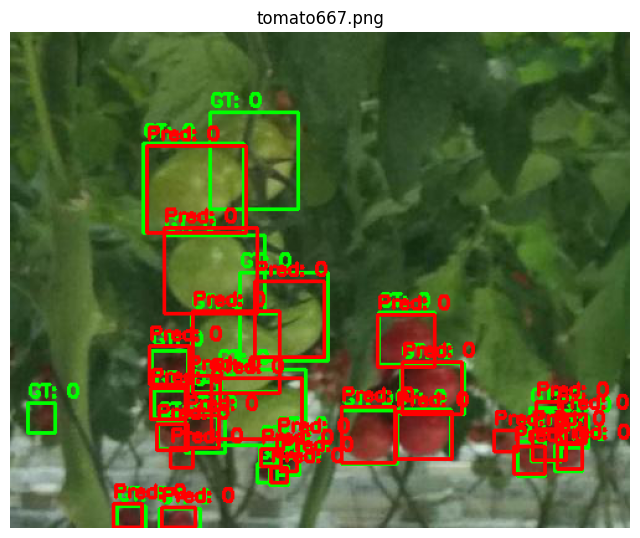

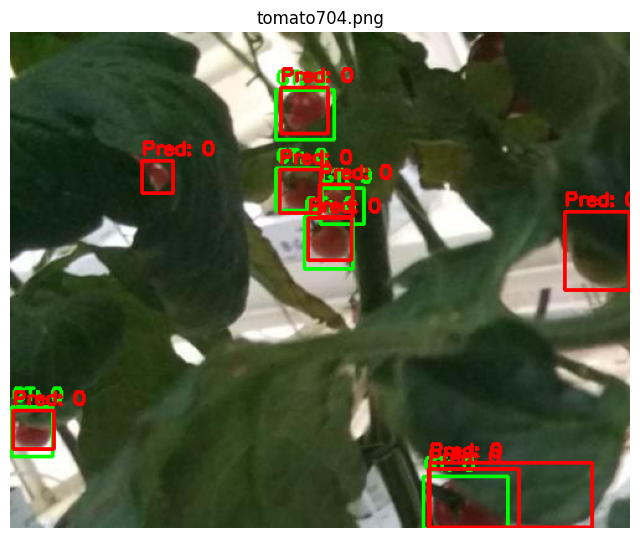

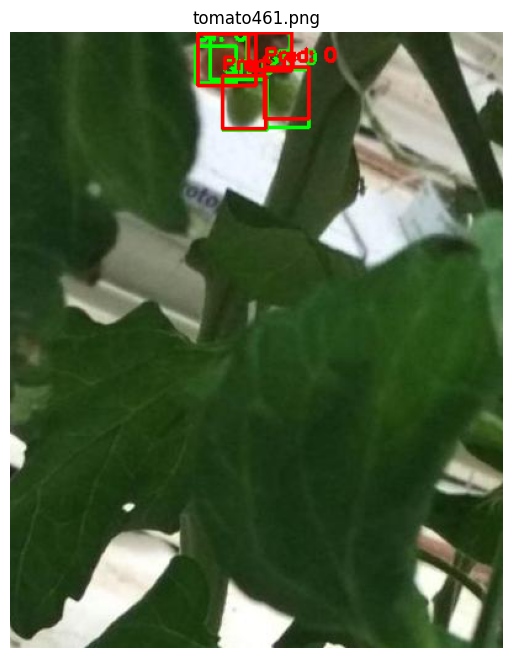

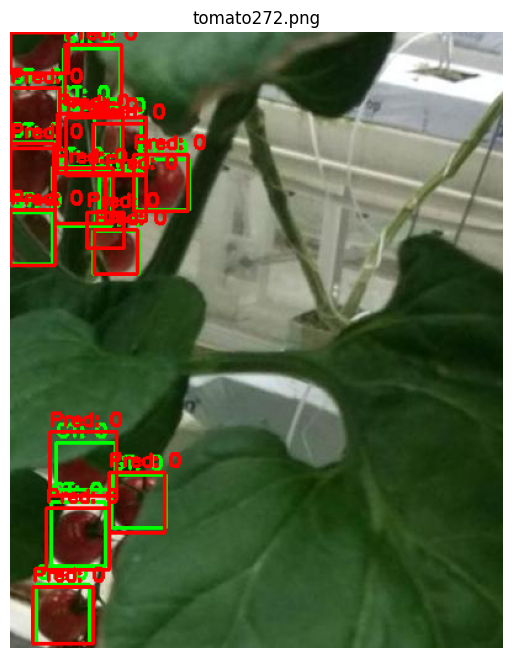

In [32]:
import os
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

sample_img_dir = './Tomato/sample/images'
gt_sample_label_dir = './Tomato/sample/labels'
pred_sample_label_dir = './runs/detect/sample_predictions/labels'

def draw_boxes(img, label_path, color, label_type):
    h, w = img.shape[:2]
    if not os.path.exists(label_path):
        return img
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls, xc, yc, bw, bh = map(float, parts[:5])
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, f'{label_type}: {int(cls)}', (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return img

# Show overlapped GT and prediction for all samples
sample_images = [f for f in os.listdir(sample_img_dir) if f.endswith(('.jpg', '.png'))]

for img_name in sample_images:
    base_name = os.path.splitext(img_name)[0]
    img_path = os.path.join(sample_img_dir, img_name)
    gt_path = os.path.join(gt_sample_label_dir, base_name + '.txt')
    pred_path = os.path.join(pred_sample_label_dir, base_name + '.txt')

    # Load image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Draw GT and predictions
    img_with_boxes = draw_boxes(img.copy(), gt_path, (0, 255, 0), 'GT')        # Green for GT
    img_with_boxes = draw_boxes(img_with_boxes, pred_path, (255, 0, 0), 'Pred') # Blue for prediction

    # Display
    plt.figure(figsize=(8, 8))
    plt.imshow(img_with_boxes)
    plt.title(img_name)
    plt.axis('off')
    plt.show()


In [30]:
full_prediction = model.predict(source = './Tomato/images/val', save=True, save_txt=True, name = 'sample_predictions')


image 1/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato104.png: 640x512 3 tomatos, 99.9ms
image 2/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato107.png: 640x512 2 tomatos, 60.9ms
image 3/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato109.png: 640x512 3 tomatos, 49.0ms
image 4/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato113.png: 640x512 2 tomatos, 52.0ms
image 5/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato120.png: 640x512 1 tomato, 49.3ms
image 6/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato121.png: 640x512 2 tomatos, 53.6ms
image 7/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato124.png: 640x512 12 tomatos, 48.2ms
image 8/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato125.png: 512x640 22 tomatos, 49.8ms
image 9/179 /Users/rokiialaa/Downloads/Tomato/Tomato/images/val/tomato127.png: 512x640 1 tomato, 48.0ms
image 10/179 /Users/rokiialaa/Downloads/Tomato/Tomato/

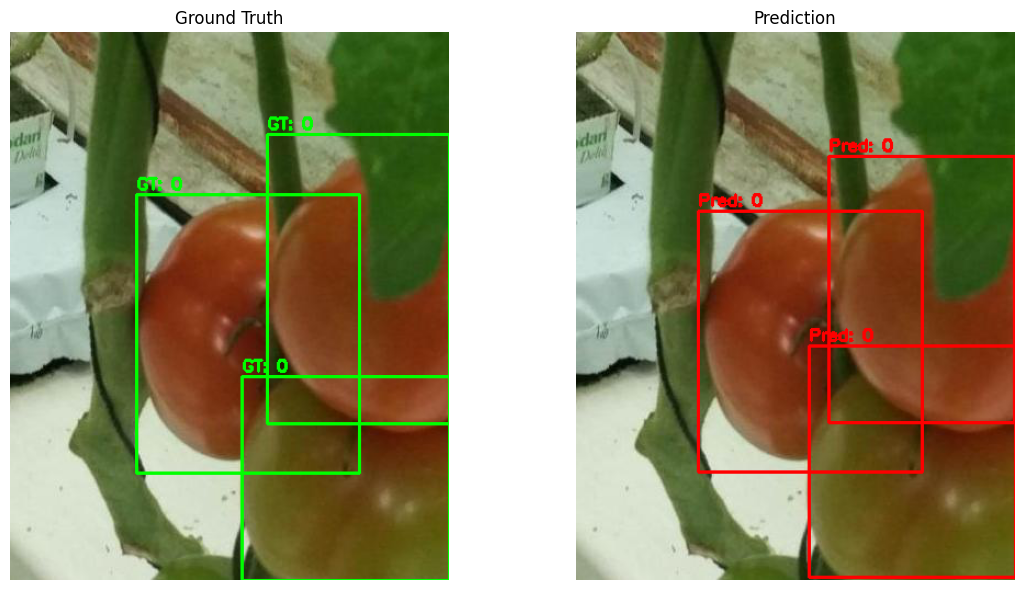

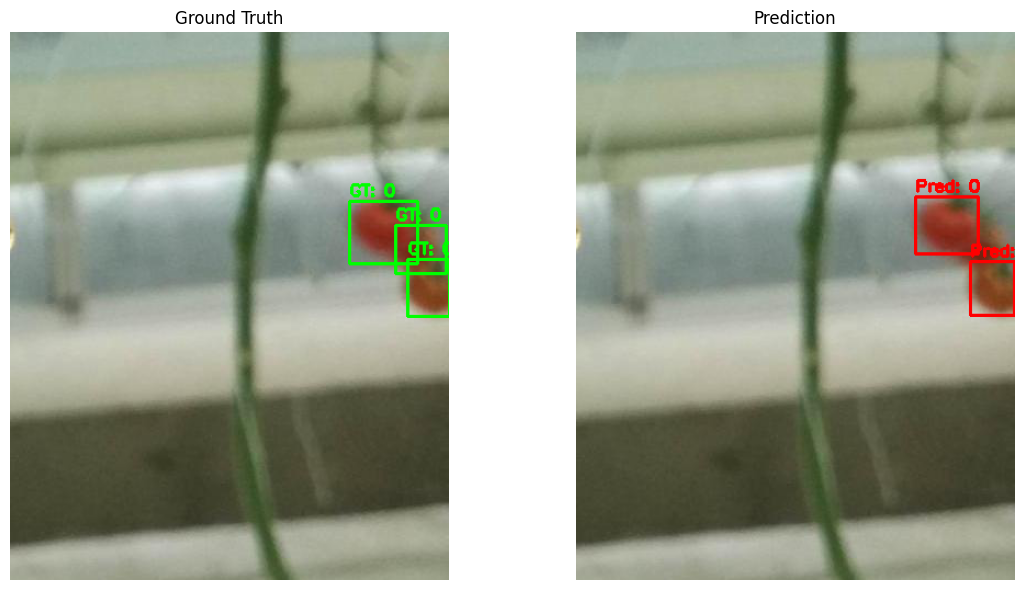

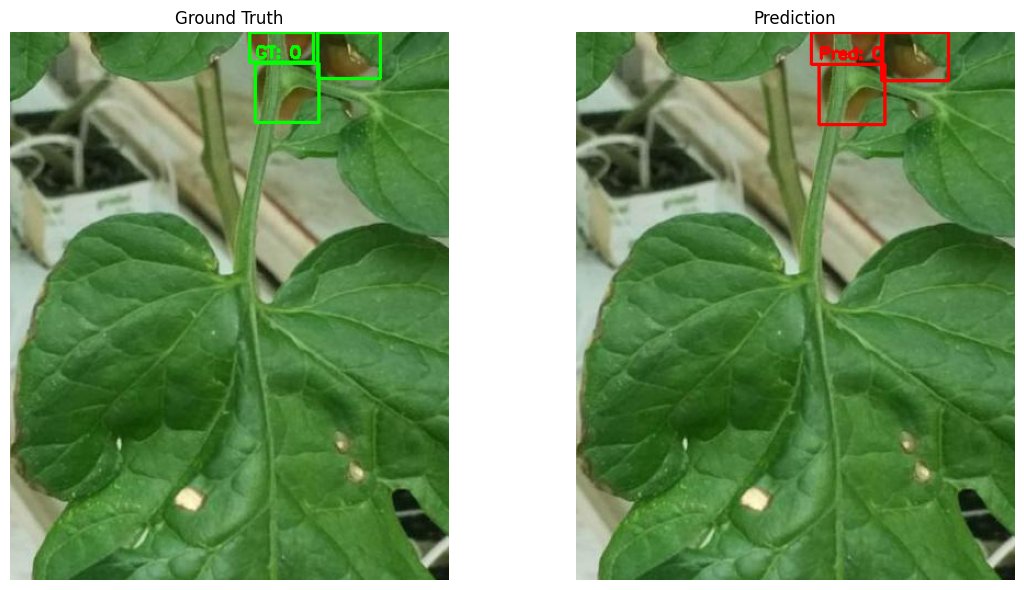

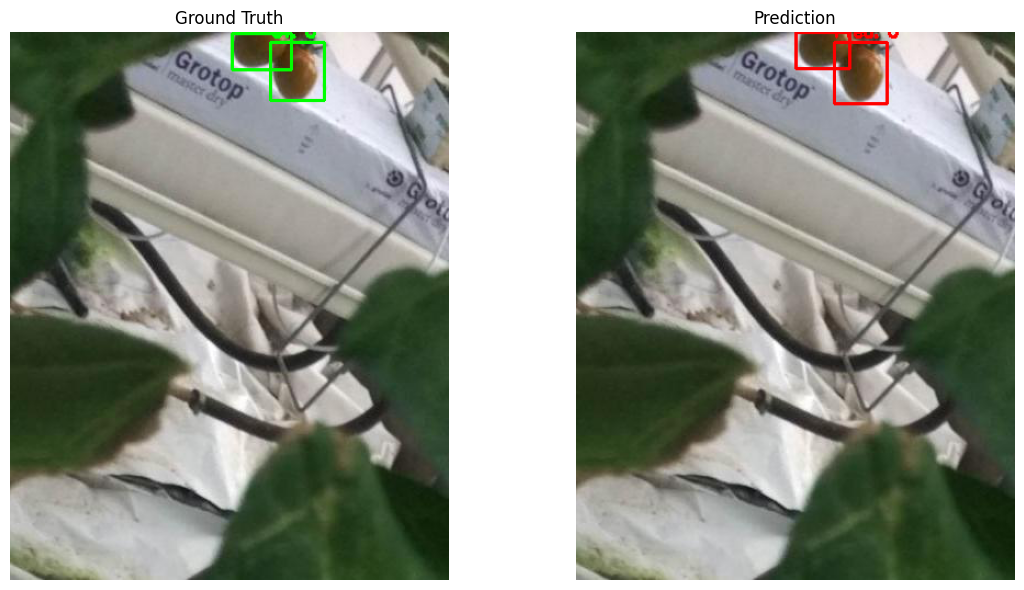

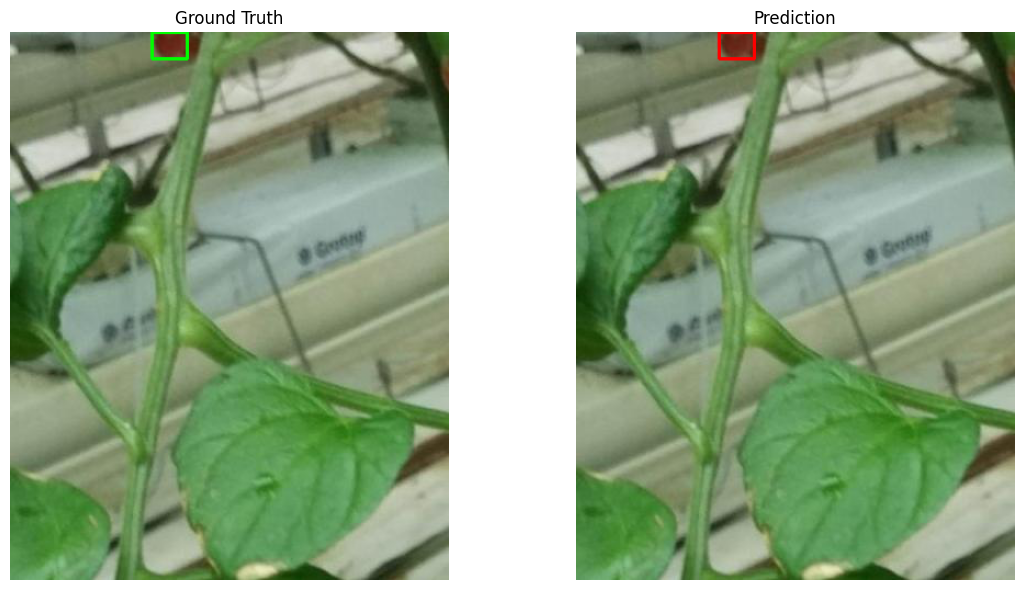

In [33]:
img_dir = './Tomato/images/val'
gt_dir = './Tomato/labels/val'
pred_dir = './runs/detect/sample_predictions2/labels'

image_files = sorted(os.listdir(img_dir))[:5]

# Loop through images
for img_file in image_files:
    base = os.path.splitext(img_file)[0]
    img_path = os.path.join(img_dir, img_file)
    gt_path = os.path.join(gt_dir, base + '.txt')
    pred_path = os.path.join(pred_dir, base + '.txt')

    # Read and draw
    img_gt = cv2.imread(img_path)
    img_gt = cv2.cvtColor(img_gt, cv2.COLOR_BGR2RGB)
    img_pred = img_gt.copy()

    img_gt = draw_boxes(img_gt, gt_path, (0, 255, 0), 'GT')
    img_pred = draw_boxes(img_pred, pred_path, (255, 0, 0), 'Pred')

    # Plot side-by-side
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    axs[0].imshow(img_gt)
    axs[0].set_title('Ground Truth')
    axs[0].axis('off')

    axs[1].imshow(img_pred)
    axs[1].set_title('Prediction')
    axs[1].axis('off')

    plt.tight_layout()
    plt.show()

In [3]:
from ultralytics import YOLO

In [4]:
model = YOLO('runs/detect/train3/weights/best.pt')

/opt/anaconda3/envs/KNCVU/lib/python3.11/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [7]:
val = model.val(data='./Tomato/data.yaml', save=True, save_txt=True, name='val_predictions')

Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 526.5±47.1 MB/s, size: 197.1 KB)


val: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/labels/val.cache... 179 images, 0 backgrounds, 0 corrupt: 100%|██████████| 179/179 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 12/12 [00:26<00:00,  2.23s/it]


                   all        179       1026      0.868      0.822      0.906      0.563
Speed: 1.0ms preprocess, 136.5ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to runs/detect/val_predictions


In [8]:
sample_val = model.val(data='./Tomato/sample.yaml', save=True, save_txt=True, name='sample_val_predictions')

Ultralytics 8.3.169 🚀 Python-3.11.13 torch-2.7.1 CPU (Apple M2)
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 601.5±45.6 MB/s, size: 216.3 KB)


val: Scanning /Users/rokiialaa/Downloads/Tomato/Tomato/sample/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100%|██████████| 10/10 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  1.09it/s]


                   all         10         75      0.858      0.907      0.942       0.53
Speed: 1.4ms preprocess, 78.9ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to runs/detect/sample_val_predictions4


In [13]:
print("\nSAMPLE vs FULL DATASET METRICS")
print(f"Sample  mAP@0.5: {sample_val.box.map50:.4f}")
print(f"Full    mAP@0.5: {val.box.map50:.4f}")
print(f"Sample  mAP@0.5:0.95: {sample_val.box.map:.4f}")
print(f"Full    mAP@0.5:0.95: {val.box.map:.4f}")
print(f"Sample  Precision: {sample_val.box.p.mean():.4f}")
print(f"Full    Precision: {val.box.p.mean():.4f}")
print(f"Sample  Recall: {sample_val.box.r.mean():.4f}")
print(f"Full    Recall: {val.box.r.mean():.4f}")



SAMPLE vs FULL DATASET METRICS
Sample  mAP@0.5: 0.9423
Full    mAP@0.5: 0.9057
Sample  mAP@0.5:0.95: 0.5301
Full    mAP@0.5:0.95: 0.5632
Sample  Precision: 0.8577
Full    Precision: 0.8680
Sample  Recall: 0.9067
Full    Recall: 0.8216


detection model performs well overall, 
correctly identifying most tomatoes in both the sample and the full dataset. 

On the sample set, it finds about 94% of tomatoes when we allow some looseness in the boxes (mAP@0.5), 
and about 91% of all real tomatoes are detected (recall). 

On the full dataset, the mAP@0.5 drops slightly to 90%, 
and recall falls to 82%, meaning we miss more tomatoes in real-world conditions. 

Precision stays high in both cases (around 86–87%), so when the model predicts a tomato, it’s usually correct. 

The slightly higher strict-accuracy score (mAP@0.5:0.95) on the full dataset shows it sometimes places boxes more precisely there, but overall the sample set is easier, which is why recall is higher on it.

